In [ ]:
file.exists("/content/WheresCroc_1.2.2.tar.gz")

[1] TRUE

In [ ]:
#install the game package
install.packages("/content/WheresCroc_1.2.2.tar.gz",
                 repos = NULL,
                 type = "source")

#load the package
library(WheresCroc)

#check the version
packageVersion("WheresCroc")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



[1] ‘1.2.2’

In [ ]:

#create the transition matrix
createTransitionMatrix <- function(edges, nStates = 40) {

    transitionMatrix <- matrix(0, nrow = nStates, ncol = nStates)

    #croc can stay in the same waterhole
    for (i in 1:nStates) {
        transitionMatrix[i, i] <- 1
    }

    #add connections between waterholes
    for (i in 1:nrow(edges)) {
        from <- edges[i, 1]
        to <- edges[i, 2]

        transitionMatrix[from, to] <- 1
        transitionMatrix[to, from] <- 1
    }

    #give equal probability to each possible move
    for (i in 1:nStates) {
        total <- sum(transitionMatrix[i, ])
        transitionMatrix[i, ] <- transitionMatrix[i, ] / total
    }

    return(transitionMatrix)
}


In [ ]:

#predict the crocodile's next location
predictCrocLocation <- function(currentProbs, transitionMatrix) {

    nStates <- length(currentProbs)
    newProbs <- rep(0, nStates)

    #calculate the probability for each waterhole
    for (j in 1:nStates) {
        newProbs[j] <- sum(currentProbs * transitionMatrix[, j])
    }

    #make sure probabilities sum to 1
    newProbs <- newProbs / sum(newProbs)

    return(newProbs)
}


In [ ]:

#initialize the HMM model
initializeModel <- function(moveInfo, edges, nStates = 40) {

    mem <- moveInfo$mem

    #create the transition matrix once
    if (is.null(mem$transitionMatrix)) {
        mem$transitionMatrix <- createTransitionMatrix(edges, nStates)
    }

    #reset probabilities at the start of a new game
    if (mem$status == 0 || mem$status == 1) {
        mem$stateProb <- rep(1 / nStates, nStates)
    }

    #mark the model as initialized
    mem$status <- 2

    moveInfo$mem <- mem

    return(moveInfo)
}


In [ ]:
# This function deals with:
# ⁠process sensor
# and ⁠updating the probabilities based on observations

updateProbabilities <- function(currentProbs, waterprobs, sensor){

  likelihood <- rep(1,length(currentProbs))
  # we go through each sensor to predict Croc's location
  for (s in 1:length(sensor)){
    # we calculate how likely the sensor its at each waterhole using its mean and standard deviation
    liklwaterprob <- dnorm(sensor[s],waterprobs[[s]][,1], waterprobs[[s]][,2])
    # now we need to calculate the likelihood and the liklwaterprob and add it to our current likelihood
    likelihood = likelihood * liklwaterprob
  }

  # finally after we have all the sensor updates
  # we update the croc probabilities to have all the probabilities in consideration
  updatedprob = likelihood * currentProbs
  # We need the distribution to add up to 1:
  totalprob = sum(updatedprob)
  updatedprob = updatedprob / totalprob

  # we return what we are interested in
  return(updatedprob)
}


In [ ]:
# This function deals with:
# Handling tourist information
# Normalize probabilities
# Manage probability storage
# ⁠updating the probabilities based on observations

updatetouristProbabilities <- function(currentProbs, pos){
  # we need from the position only the values that represent the tourist
  tourist <- pos[1:2]

  # Now we need to find the state of our tourist and if they have been eaten (RIP)
  for (t in 1:length(tourist)){
    # if position positive is alive
    if ((!is.na(tourist[t])) & tourist[t] > 0){
      currentProbs[tourist[t]] = 0
    }
    # if eaten
    else if((!is.na(tourist[t])) & tourist[t] < 0){
      # we need to restart, in a way is like if we got a new clue where it is, we dont care about previous state
      currentProbs = rep(0,length(currentProbs))
      #we transform our negative position, where the tourist was eaten, to positive to know where the eating had happened
      currentProbs[abs(tourist[t])] = 1
    }
    # if NA we (go to the next tourist) just wait for something to happen (negligence)
  }
  # we just do what we did before
  touristtotalprob = sum(currentProbs)

  if (touristtotalprob != 0){
    currentProbs = currentProbs / touristtotalprob
  }
  #to avoid division by zero in case (just in case, but i dont think it will be needed for this task),
  # ill create this branch to give probabilities if the result would be zero
  else{
    currentProbs = rep(1,length(currentProbs))
    # we need this again to avoid the same mistake again
    for (t in 1:length(tourist)){
        # if position positive is alive
      if ((!is.na(tourist[t])) & tourist[t] > 0){
          currentProbs[tourist[t]] = 0
        }
    }
    fbtouristtotalprob = sum(currentProbs)
    currentProbs = currentProbs / fbtouristtotalprob
  }

  return(currentProbs)
}

In [ ]:
# This function deals with:
# Handling unsuccessful ranger searches
# Normalizing probabilities

updateSearchProbabilities <- function(currentProbs, searched){

  # if Croc wasnt found, we remove those waterholes
  currentProbs[searched] = 0

  # normalize the probabilities
  totalprob = sum(currentProbs)

  if (totalprob > 0){
    currentProbs = currentProbs / totalprob
  }

  else{
  # if all probabilities are zero, we start again
  currentProbs = rep(1,length(currentProbs))

  # exclude the searched waterholes
  currentProbs[searched] = 0

  # normalize again
  fbtotalprob = sum(currentProbs)
  currentProbs = currentProbs / fbtotalprob
}


  return(currentProbs)
}

In [ ]:
# this function connects all three parts of our game

myFunction <- function(moveInfo, sensor, pos, edges, waterprobs){

  # we check if this is the first turn
  firstTurn = moveInfo$mem$status %in% c(0,1) ||
              is.null(moveInfo$mem$stateProb)

  # we initialize the model
  moveInfo = initializeModel(moveInfo, edges)

  # we get the probabilities from memory
  currentProbs = moveInfo$mem$stateProb

  # if Croc has already moved before, we update our prediction
  if (!firstTurn){

    # we remove the waterholes where the ranger searched last turn
    searched = moveInfo$mem$searchedHoles

    if (length(searched) > 0){
      currentProbs = updateSearchProbabilities(currentProbs, searched)
    }

    # And we predict Croc's new location
    currentProbs = predictCrocLocation(
      currentProbs, moveInfo$mem$transitionMatrix
    )
  }

  # we update the probabilities using sensor information
  currentProbs = updateProbabilities(currentProbs, waterprobs, sensor)

  # we update the probabilities using tourist information
  currentProbs = updatetouristProbabilities(currentProbs, pos)

  # we save our updated probabilities into mem
  moveInfo$mem$stateProb = currentProbs


  ranger <- pos[3]   # where the ranger is

  # build the walking table
  if (is.null(moveInfo$mem$nextStep)) {    # since we only want to do this once
    nStates <- 40
    both <- rbind(edges, edges[, 2:1])    # essentially concatinating, adding the edges both ways so we can search bidirectionally
    neighbours <- split(both[, 2], factor(both[, 1]))    # this is a little confusing, but its basically making the R equivalent of making a python dictionary of all waterholes, with all their neighbors as values

    dist <- matrix(67, nStates, nStates)    # 67 works as a placeholder and informs that we have not visited that neighbor before (the number 67 is completely arbitrary)
    nextStep <- matrix(0, nStates, nStates)   # we don't know where to go yet, sorry

    for (goal in 1:nStates) {
      dist[goal, goal] <- 0    # the goal is at 0 because we dont have any distance left if we're at the goal
      queue <- goal
      while (length(queue) > 0) {    # we can't search an empty queue, duuuuh
        current_hole <- queue[1]    # moving the queue forward, current is now the first item in queue
        queue <- queue[-1]    # remove the first item as we are currently looking at it
        for (bestie in neighbours[[current_hole]]) {    # here we check every neighbor for our current hole

          if (dist[bestie, goal] == 67) {    # basically: have we found a way here yet? we're literally checking if it is equal to 67, which is how we mark unseen
            dist[bestie, goal] <- dist[current_hole, goal] + 1    # here we make 67 something tangiable, since bestie has to be further away from current (because of the if statement), we add a 1 to its value, since its one step from current
            nextStep[bestie, goal] <- current_hole    # if we're at this bestie, we know the way to the goal is best found through current positon
            queue <- c(queue, bestie)    # combine by putting bestie at the end of the list
          }
        }
      }
    }
    # tuck those babies away safely
    moveInfo$mem$nextStep <- nextStep
    moveInfo$mem$dist <- dist
  }

  # pick the most likely hole to find croc
  target <- which.max(currentProbs)

  # let's try to get there!
  ns <- moveInfo$mem$nextStep
  step1 <- ns[ranger, target]    # we mooooove (hopefully) towards croc

  searched <- integer(0)    # we havent actually checked anyhting yet

  if (step1 == 0) {    # if we have reached the goal
    moves <- c(0, 0)    # let's search this waterhole!
    searched <- ranger    # store the waterhole
  } else {    # if we're not yet at the target :(
    step2 <- ns[step1, target]    # where we should go after moving in step1
    moves <- c(step1, step2)    # store our movezzz

    if (step2 == 0) {    # if we reached the target
        searched <- step1    # searchhhh
    }
  }


  # we ofc have to remember what we searched
  moveInfo$mem$searchedHoles <- searched

  # sooo... where should we go?
  moveInfo$moves <- moves
  return(moveInfo)

}

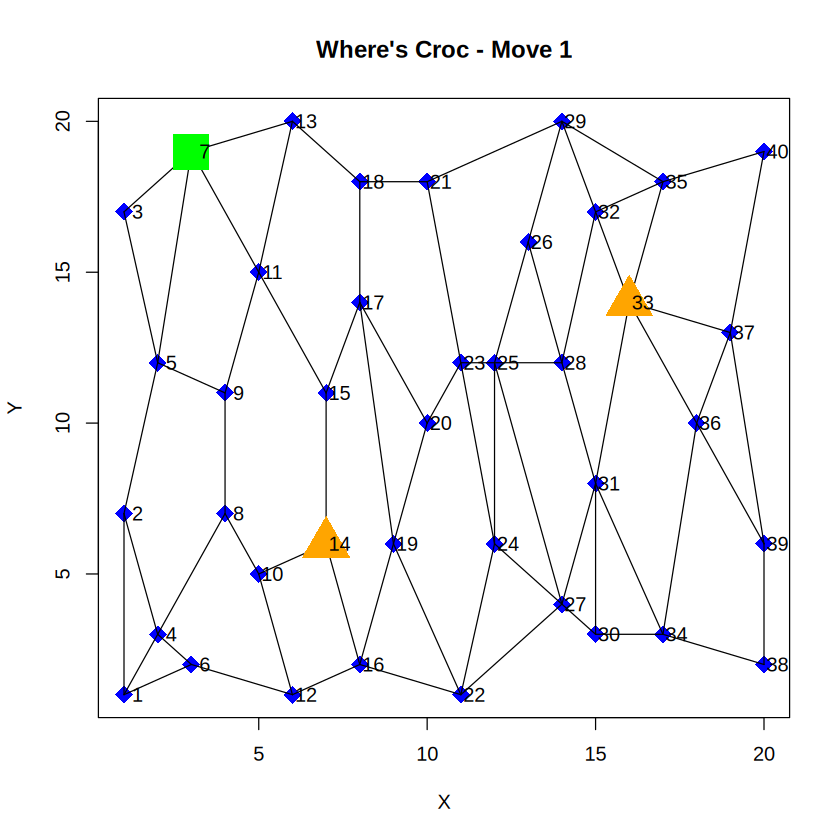


Congratualations - You got croc at move  2

[1] 2

[1] 4.386

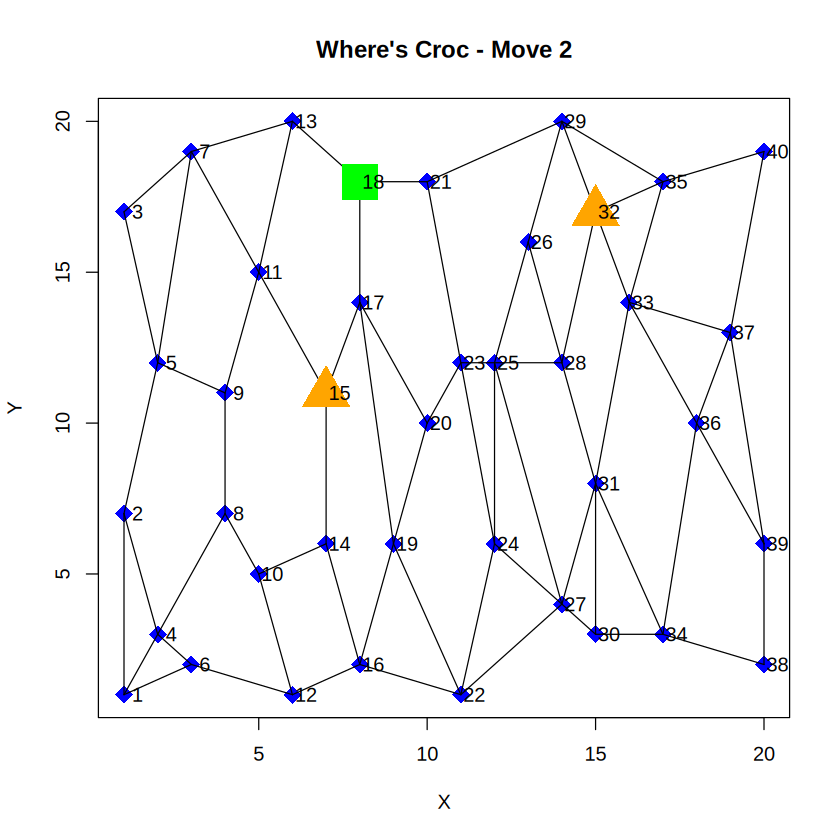

In [ ]:
set.seed(67)
runWheresCroc(myFunction, doPlot = TRUE, pause = 1)
testWC(myFunction)